# UltraSam2 Segmentation Metrics — Denoised Input
Compares UltraSam2 predicted nerve masks against hand-drawn ground truth.

**Metrics:** IoU, Dice, Hausdorff Distance, mAP / mAP@50  
**GT source:** AlmeidaDenoised2_nerve, BorgesDenoised2_nerve, BritoDenoised2_nerve  
**Predictions:** `D:/ultrasam2-results/inference1_dn/<patient>/masks/`  
**Source images:** Speckle2Self denoised — `speckle2self-results/git_val/260720-cropped4/epoch199/<patient>/`

In [36]:
import os
import re
import numpy as np
import pandas as pd
from PIL import Image
from scipy.spatial.distance import directed_hausdorff

In [37]:
# ── Paths ────────────────────────────────────────────────────────────────────
GT_ROOT   = r"D:\annotated_pn"
PRED_ROOT = r"D:\ultrasam2-results\inference1_dn"

PATIENTS = {
    "Almeida": "AlmeidaDenoised2_nerve",
    "Borges":  "BorgesDenoised2_nerve",
    "Brito":   "BritoDenoised2_nerve",
}

LABEL_MAP = {"Almeida": "Patient 1", "Borges": "Patient 2", "Brito": "Patient 3"}

In [38]:
# ── Metric functions ─────────────────────────────────────────────────────────

def compute_iou(pred: np.ndarray, gt: np.ndarray) -> float:
    p, g = pred.astype(bool), gt.astype(bool)
    inter = np.logical_and(p, g).sum()
    union = np.logical_or(p, g).sum()
    return float(inter / union) if union > 0 else 1.0


def compute_dice(pred: np.ndarray, gt: np.ndarray) -> float:
    p, g = pred.astype(bool), gt.astype(bool)
    inter = np.logical_and(p, g).sum()
    denom = p.sum() + g.sum()
    return float(2 * inter / denom) if denom > 0 else 1.0


def compute_hausdorff(pred: np.ndarray, gt: np.ndarray) -> float:
    """Symmetric Hausdorff distance in pixels. Returns NaN if either mask is empty."""
    pred_pts = np.column_stack(np.where(pred.astype(bool)))
    gt_pts   = np.column_stack(np.where(gt.astype(bool)))
    if len(pred_pts) == 0 or len(gt_pts) == 0:
        return float("nan")
    return max(
        directed_hausdorff(pred_pts, gt_pts)[0],
        directed_hausdorff(gt_pts, pred_pts)[0],
    )


MAP_THRESHOLDS = np.arange(0.50, 1.00, 0.05)

def compute_map(iou_scores: np.ndarray) -> tuple:
    """Returns (mAP, mAP@50) from an array of per-frame IoU scores."""
    ap_per_thresh = [(iou_scores >= t).mean() for t in MAP_THRESHOLDS]
    return float(np.mean(ap_per_thresh)), float(ap_per_thresh[0])


def load_binary(path) -> np.ndarray:
    return (np.array(Image.open(path).convert('L')) > 0)

In [39]:
# ── Build match table ─────────────────────────────────────────────────────────
# GT filename:   Label_N_{base}_denoised.png      → key: {base}
# Pred filename: {base}_denoised_mask.png         → key: {base}  (strip _denoised_mask.png)

def frame_key_from_gt(fname: str) -> str:
    s = re.sub(r'^Label_\d+_', '', fname)
    return s.replace('_denoised.png', '').replace('.png', '')

def frame_key_from_pred(fname: str) -> str:
    # handles both _denoised_mask.png and _mask.png
    return fname.replace('_denoised_mask.png', '').replace('_mask.png', '')


records = []

for patient, gt_folder in PATIENTS.items():
    gt_dir   = os.path.join(GT_ROOT, gt_folder)
    pred_dir = os.path.join(PRED_ROOT, patient.lower(), "masks")

    if not os.path.exists(pred_dir):
        print(f"[SKIP] {patient}: predictions not ready at {pred_dir}")
        continue

    gt_index = {
        frame_key_from_gt(f): os.path.join(gt_dir, f)
        for f in os.listdir(gt_dir) if f.endswith('.png')
    }
    pred_index = {
        frame_key_from_pred(f): os.path.join(pred_dir, f)
        for f in os.listdir(pred_dir) if f.endswith('.png')
    }

    for gt_key, gt_path in gt_index.items():
        pred_path = pred_index.get(gt_key)
        if pred_path is None:
            print(f"  [WARN] No prediction for GT key: {gt_key} ({patient})")
            continue
        records.append({
            "patient":   patient,
            "frame_key": gt_key,
            "gt_path":   gt_path,
            "pred_path": pred_path,
        })

df = pd.DataFrame(records)
print(f"Total annotated frames matched: {len(df)}")
print(df.groupby('patient').size().rename('frames'))

Total annotated frames matched: 134
patient
Almeida    42
Borges     49
Brito      43
Name: frames, dtype: int64


In [40]:
# ── Compute per-frame metrics ─────────────────────────────────────────────────
m = df.apply(
    lambda r: pd.Series({
        'iou':       compute_iou(load_binary(r['pred_path']), load_binary(r['gt_path'])),
        'dice':      compute_dice(load_binary(r['pred_path']), load_binary(r['gt_path'])),
        'hausdorff': compute_hausdorff(load_binary(r['pred_path']), load_binary(r['gt_path'])),
    }), axis=1
)
df = df.join(m)

print("Metrics computed.")
print(df[['patient', 'iou', 'dice', 'hausdorff']].head(5))

Metrics computed.
   patient       iou      dice  hausdorff
0  Almeida  0.413620  0.585193  27.000000
1  Almeida  0.341535  0.509171  32.984845
2  Almeida  0.313010  0.476782  33.105891
3  Almeida  0.649496  0.787508  14.317821
4  Almeida  0.290933  0.450733  39.115214


In [41]:
# ── Aggregate: mean ± std per patient ────────────────────────────────────────

def summarise(group_df):
    iou  = group_df['iou'].dropna()
    dice = group_df['dice'].dropna()
    hd   = group_df['hausdorff'].dropna()
    map_, map50 = compute_map(iou.values)
    return pd.Series({
        'n':       len(iou),
        'IoU':     f"{iou.mean():.3f} ± {iou.std():.3f}",
        'Dice':    f"{dice.mean():.3f} ± {dice.std():.3f}",
        'HD (px)': f"{hd.mean():.1f} ± {hd.std():.1f}",
        'mAP':     f"{map_:.3f}",
        'mAP@50':  f"{map50:.3f}",
    })


rows = {LABEL_MAP[p]: summarise(gdf) for p, gdf in df.groupby('patient')}
rows['OVERALL'] = summarise(df)
summary = pd.DataFrame(rows).T

print("UltraSam2 (denoised) — predictions vs GT")
print(summary.to_string())

UltraSam2 (denoised) — predictions vs GT
             n            IoU           Dice      HD (px)    mAP mAP@50
Patient 1   42  0.413 ± 0.105  0.578 ± 0.103  31.4 ± 11.8  0.033  0.119
Patient 2   49  0.626 ± 0.117  0.763 ± 0.095  18.0 ± 10.3  0.324  0.857
Patient 3   43  0.602 ± 0.099  0.747 ± 0.078  23.9 ± 12.0  0.258  0.814
OVERALL    134  0.552 ± 0.142  0.700 ± 0.124  24.1 ± 12.5  0.212  0.612


In [42]:
# ── Raw numeric values + CSV export ──────────────────────────────────────────

def summarise_raw(group_df):
    iou  = group_df['iou'].dropna()
    dice = group_df['dice'].dropna()
    hd   = group_df['hausdorff'].dropna()
    map_, map50 = compute_map(iou.values)
    return pd.Series({
        'n':          len(iou),
        'IoU_mean':   round(iou.mean(),  4),
        'IoU_std':    round(iou.std(),   4),
        'Dice_mean':  round(dice.mean(), 4),
        'Dice_std':   round(dice.std(),  4),
        'HD_mean_px': round(hd.mean(),   2),
        'HD_std_px':  round(hd.std(),    2),
        'mAP':        round(map_,        4),
        'mAP@50':     round(map50,       4),
    })


rows_raw = {LABEL_MAP[p]: summarise_raw(gdf) for p, gdf in df.groupby('patient')}
rows_raw['OVERALL'] = summarise_raw(df)
summary_raw = pd.DataFrame(rows_raw).T
print(summary_raw.to_string())

summary_raw.to_csv(r"D:\ultrasam2-results\ultrasam2_metrics_dn.csv")
print("\nSaved → D:\\ultrasam2-results\\ultrasam2_metrics_dn.csv")

               n  IoU_mean  IoU_std  Dice_mean  Dice_std  HD_mean_px  HD_std_px     mAP  mAP@50
Patient 1   42.0    0.4135   0.1049     0.5776    0.1026       31.36      11.80  0.0333  0.1190
Patient 2   49.0    0.6255   0.1166     0.7630    0.0947       18.04      10.31  0.3245  0.8571
Patient 3   43.0    0.6024   0.0992     0.7472    0.0779       23.94      12.01  0.2581  0.8140
OVERALL    134.0    0.5516   0.1424     0.6998    0.1237       24.11      12.53  0.2119  0.6119

Saved → D:\ultrasam2-results\ultrasam2_metrics_dn.csv


In [ ]:
# ── XLSX export — sheet "Denoised" in ultrasam2_metrics.xlsx ─────────────────
from openpyxl.utils import get_column_letter

xlsx_path = os.path.join(OUT_DIR, 'ultrasam2_metrics.xlsx')
ew_kwargs = dict(engine='openpyxl', mode='a', if_sheet_exists='replace') \
    if os.path.exists(xlsx_path) else dict(engine='openpyxl')
with pd.ExcelWriter(xlsx_path, **ew_kwargs) as writer:
    summary.to_excel(writer, sheet_name='Denoised', startrow=0)
    summary_raw.to_excel(writer, sheet_name='Denoised', startrow=len(summary) + 2)
    ws = writer.sheets['Denoised']
    for col_idx in range(1, ws.max_column + 1):
        col_letter = get_column_letter(col_idx)
        ws.column_dimensions[col_letter].width = max(
            (len(str(c.value)) for c in ws[col_letter] if c.value), default=8
        ) + 3
print(f'Saved → {xlsx_path}')

In [43]:
# ── Visualization helper ──────────────────────────────────────────────────────
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display as ipy_display, Image as IPyImage

SOURCE_ROOT = r"D:\dissertation-results\speckle2self-results\git_inf\260720-cropped4\epoch199"
OUT_DIR     = os.getcwd()

def source_path(patient, frame_key):
    return os.path.join(SOURCE_ROOT, patient.lower(), f"{frame_key}_denoised.png")

def make_overlay(img_arr, mask_arr, color=(0, 200, 60), alpha=0.5):
    out = img_arr.copy().astype(np.float32)
    out[mask_arr.astype(bool)] = (
        out[mask_arr.astype(bool)] * (1 - alpha)
        + np.array(color, dtype=np.float32) * alpha
    )
    return out.astype(np.uint8)

def show_patient_samples(patient, n=3, seed=42):
    rows = df[df['patient'] == patient]
    if len(rows) == 0:
        print(f"{patient}: no matched frames available")
        return
    samples = rows.sample(min(n, len(rows)), random_state=seed)

    fig, axes = plt.subplots(len(samples), 2, figsize=(11, 3.6 * len(samples)))
    if len(samples) == 1:
        axes = axes[np.newaxis, :]

    for i, (_, r) in enumerate(samples.iterrows()):
        src       = np.array(Image.open(source_path(patient, r['frame_key'])).convert('RGB'))
        gt_mask   = load_binary(r['gt_path'])
        pred_mask = load_binary(r['pred_path'])

        axes[i, 0].imshow(make_overlay(src, gt_mask))
        axes[i, 0].set_title("Ground Truth", fontsize=8)
        axes[i, 0].axis('off')
        axes[i, 1].imshow(make_overlay(src, pred_mask))
        axes[i, 1].set_title(f"IoU={r['iou']:.3f}  Dice={r['dice']:.3f}", fontsize=8)
        axes[i, 1].axis('off')

    plt.tight_layout()
    label_slug = LABEL_MAP[patient].replace(' ', '_').lower()
    out_path = os.path.join(OUT_DIR, f"{label_slug}_ultrasam2_dn_samples.png")
    fig.savefig(out_path, dpi=150, bbox_inches='tight')
    plt.close(fig)
    ipy_display(IPyImage(filename=out_path))
    print(f"Saved → {out_path}")

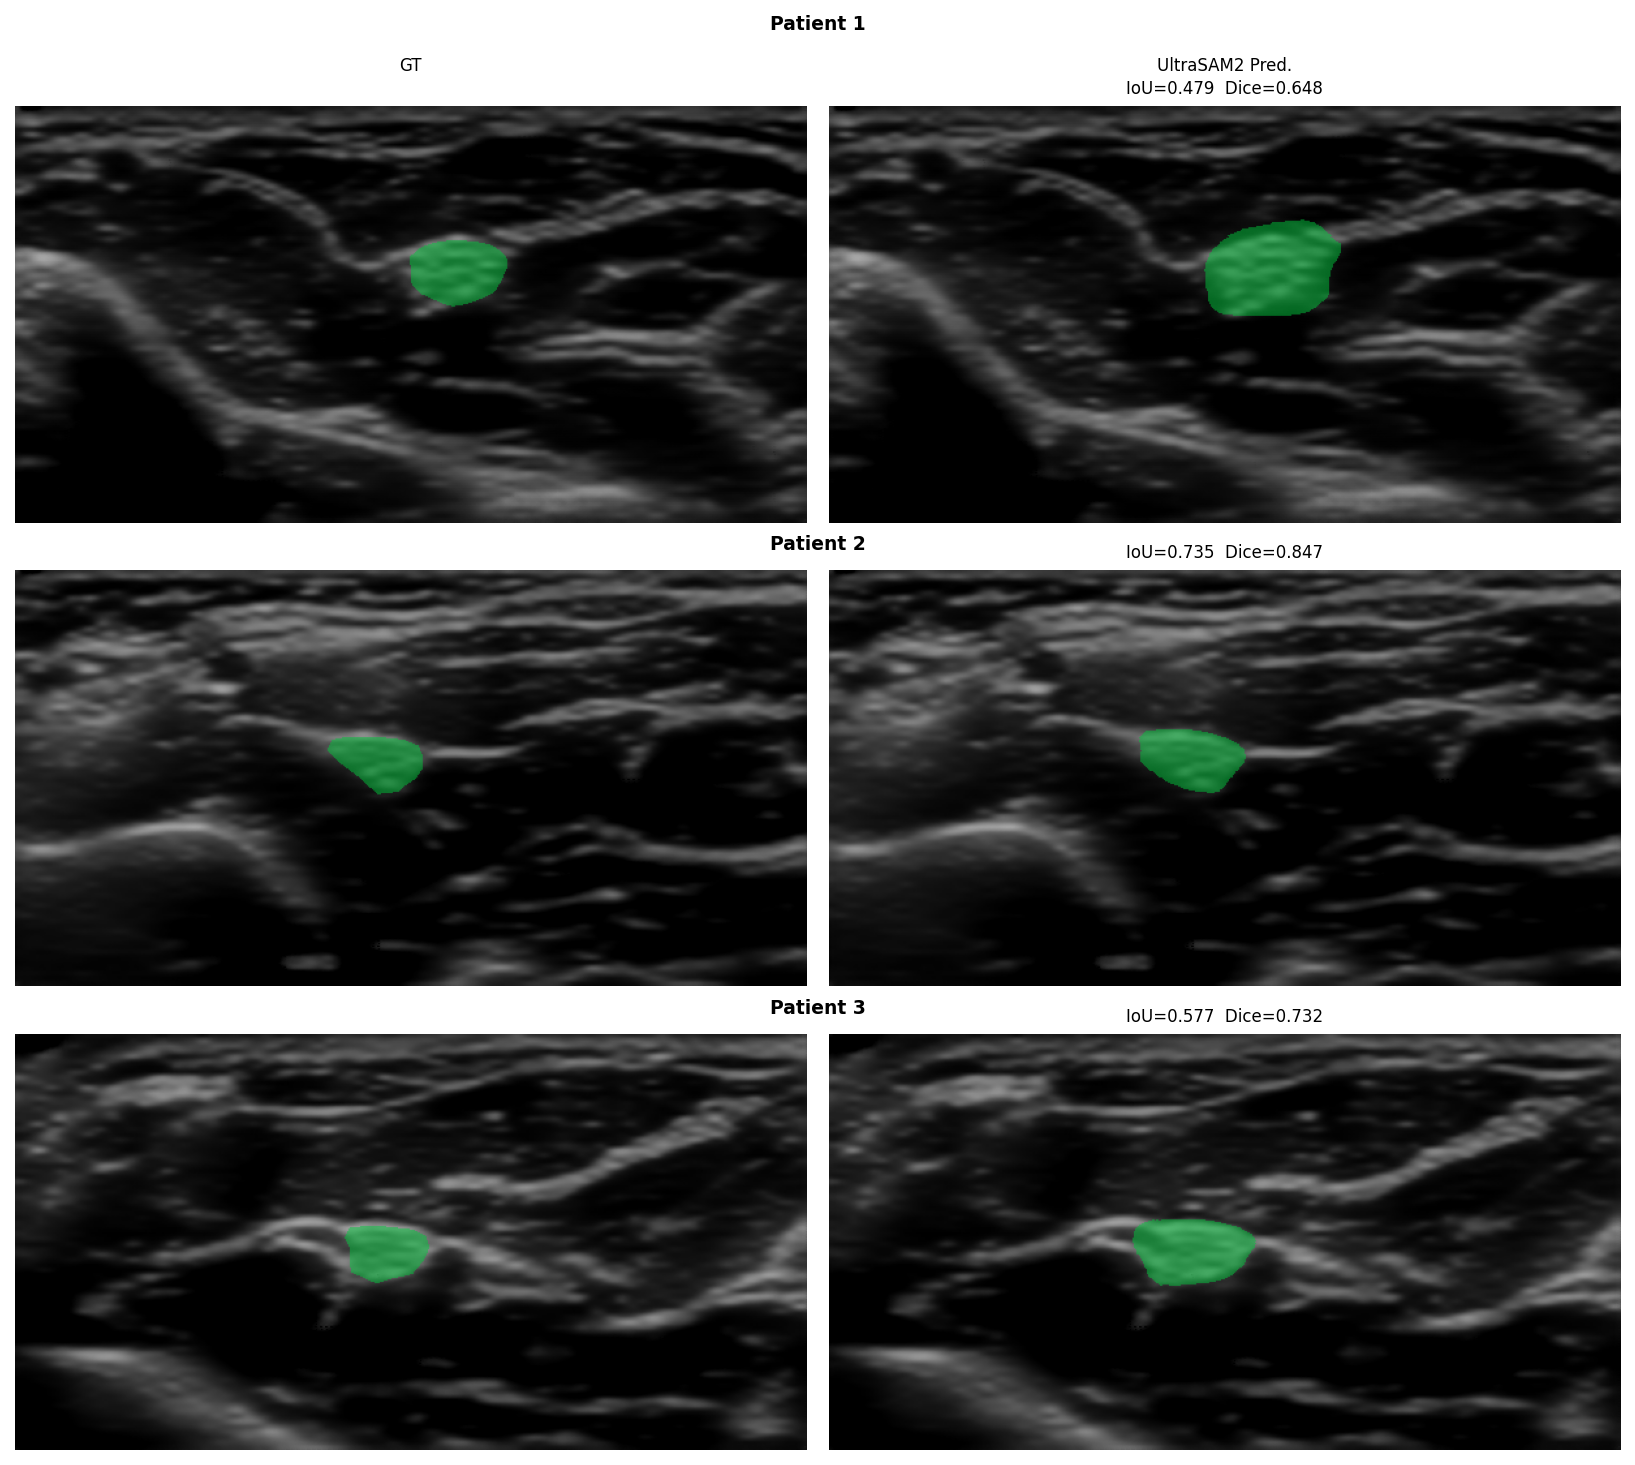

Saved → d:\graphs-n-tables\ultrasam2\ultrasam2_denoised_input_qualitative.png


In [44]:
# ── Mosaic: one random frame per patient ─────────────────────────────────────
def make_mosaic(seed=42):
    fig, axes = plt.subplots(len(PATIENTS), 2, figsize=(11, 3.6 * len(PATIENTS)))
    for row, patient in enumerate(PATIENTS):
        patient_rows = df[df['patient'] == patient]
        r = patient_rows.sample(1, random_state=seed).iloc[0]
        src       = np.array(Image.open(source_path(patient, r['frame_key'])).convert('RGB'))
        gt_mask   = load_binary(r['gt_path'])
        pred_mask = load_binary(r['pred_path'])
        axes[row, 0].imshow(make_overlay(src, gt_mask))
        axes[row, 0].axis('off')
        axes[row, 1].imshow(make_overlay(src, pred_mask))
        axes[row, 1].set_title(f"IoU={r['iou']:.3f}  Dice={r['dice']:.3f}", fontsize=8)
        axes[row, 1].axis('off')
    plt.tight_layout()
    plt.subplots_adjust(top=0.88)
    x_gt   = (axes[0, 0].get_position().x0 + axes[0, 0].get_position().x1) / 2
    x_pred = (axes[0, 1].get_position().x0 + axes[0, 1].get_position().x1) / 2
    x_mid  = (axes[0, 0].get_position().x0 + axes[0, 1].get_position().x1) / 2
    y_top_row0 = axes[0, 0].get_position().y1
    fig.text(x_gt,   y_top_row0 + 0.020, 'GT',                ha='center', va='bottom', fontsize=8)
    fig.text(x_pred, y_top_row0 + 0.020, 'UltraSAM2 Pred.',   ha='center', va='bottom', fontsize=8)
    for row, patient in enumerate(PATIENTS):
        label   = LABEL_MAP[patient]
        y_top   = axes[row, 0].get_position().y1
        y_label = y_top + 0.045 if row == 0 else y_top + 0.010
        fig.text(x_mid, y_label, label, ha='center', va='bottom', fontsize=9, fontweight='bold')
    out_path = os.path.join(OUT_DIR, "ultrasam2_denoised_input_qualitative.png")
    fig.savefig(out_path, dpi=150, bbox_inches='tight')
    plt.close(fig)
    ipy_display(IPyImage(filename=out_path))
    print(f"Saved → {out_path}")
make_mosaic()

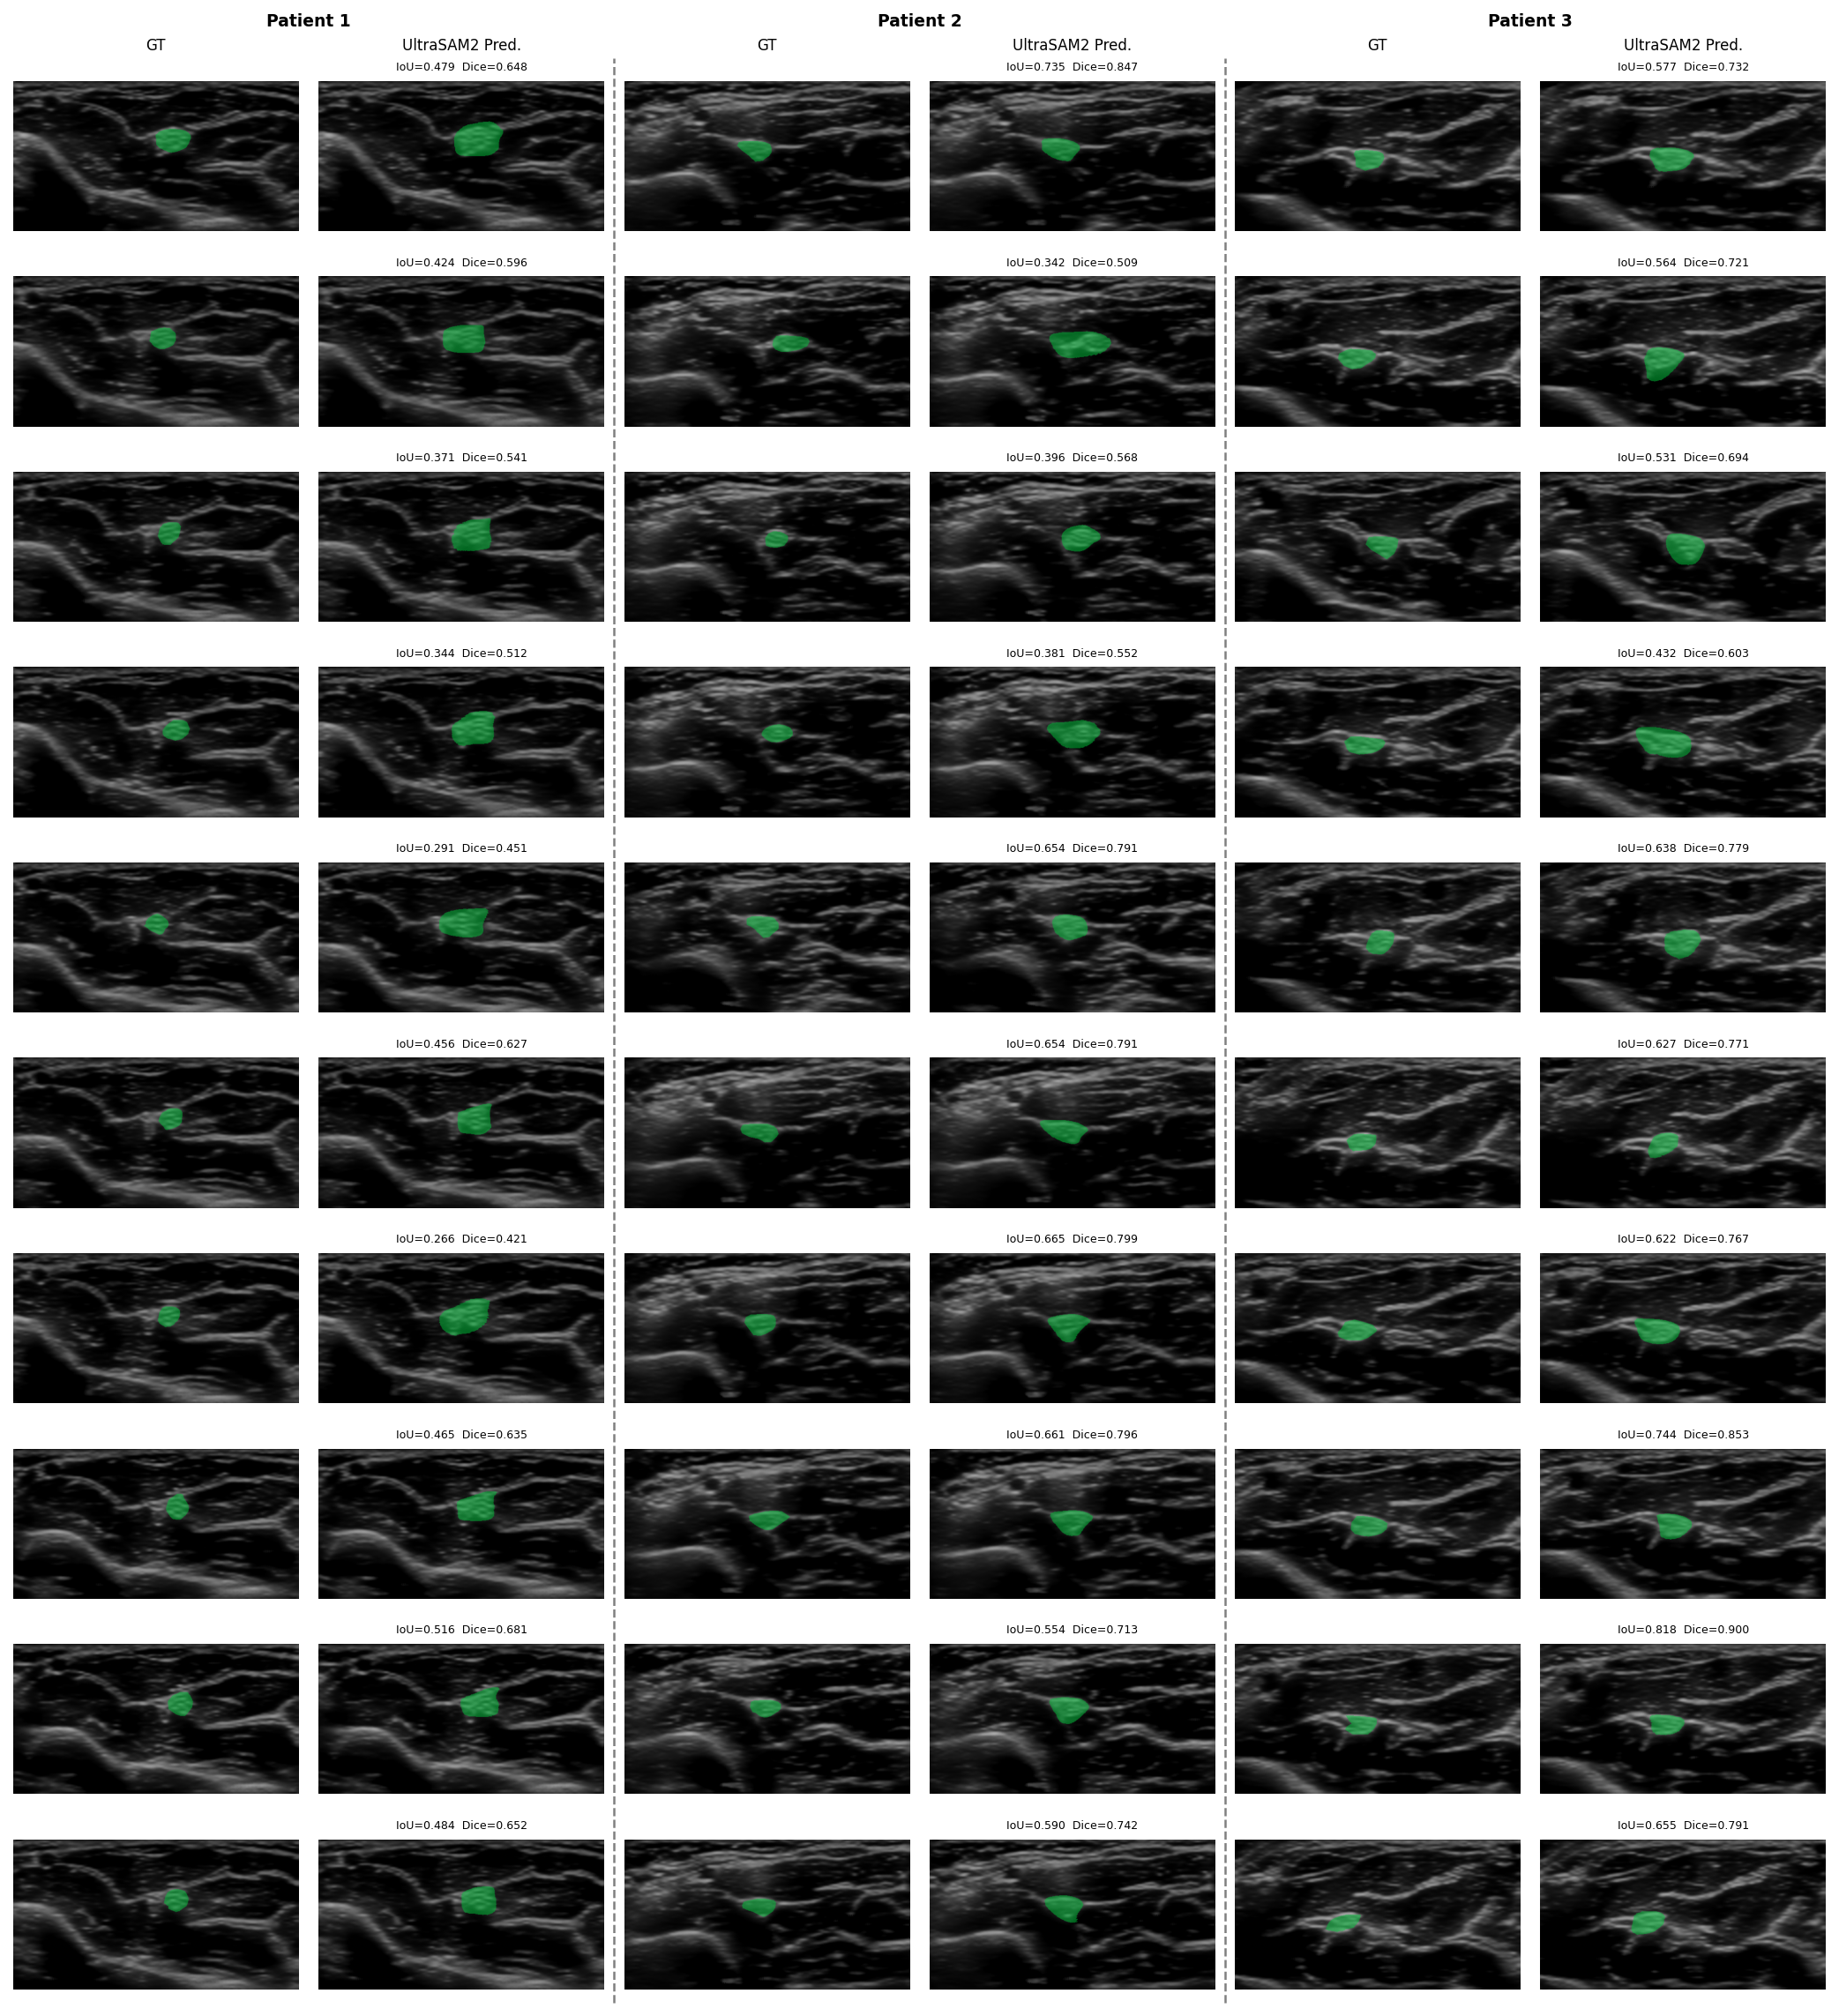

Saved → d:\graphs-n-tables\ultrasam2\ultrasam2_denoised_all_patients_grid.png


In [45]:
# ── All-patients grid: 10 frames × 3 patients (each patient = GT + prediction column) ──
from matplotlib.lines import Line2D

N_FRAMES = 10
SEED     = 42

fig, axes = plt.subplots(N_FRAMES, len(PATIENTS) * 2, figsize=(14, 1.5 * N_FRAMES))

for col_pair, patient in enumerate(PATIENTS):
    patient_rows = df[df['patient'] == patient]
    samples      = patient_rows.sample(min(N_FRAMES, len(patient_rows)), random_state=SEED)

    col_gt   = col_pair * 2
    col_pred = col_pair * 2 + 1

    for row, (_, r) in enumerate(samples.iterrows()):
        src       = np.array(Image.open(source_path(patient, r['frame_key'])).convert('RGB'))
        gt_mask   = load_binary(r['gt_path'])
        pred_mask = load_binary(r['pred_path'])

        axes[row, col_gt].imshow(make_overlay(src, gt_mask))
        axes[row, col_gt].axis('off')
        axes[row, col_pred].imshow(make_overlay(src, pred_mask))
        axes[row, col_pred].set_title(f"IoU={r['iou']:.3f}  Dice={r['dice']:.3f}", fontsize=6)
        axes[row, col_pred].axis('off')

plt.tight_layout()

y_top     = axes[0, 0].get_position().y1
y_headers = y_top + 0.014
y_patient = y_top + 0.026

for col_pair, patient in enumerate(PATIENTS):
    label    = LABEL_MAP[patient]
    col_gt   = col_pair * 2
    col_pred = col_pair * 2 + 1

    x_gt   = (axes[0, col_gt].get_position().x0   + axes[0, col_gt].get_position().x1)   / 2
    x_pred = (axes[0, col_pred].get_position().x0  + axes[0, col_pred].get_position().x1) / 2
    x_mid  = (axes[0, col_gt].get_position().x0   + axes[0, col_pred].get_position().x1)  / 2

    fig.text(x_mid,  y_patient,  label,              ha='center', va='bottom', fontsize=9, fontweight='bold')
    fig.text(x_gt,   y_headers,  'GT',               ha='center', va='bottom', fontsize=8)
    fig.text(x_pred, y_headers,  'UltraSAM2 Pred.',  ha='center', va='bottom', fontsize=8)

for sep_col in [1, 3]:
    x_left  = axes[0, sep_col].get_position().x1
    x_right = axes[0, sep_col + 1].get_position().x0
    x_mid   = (x_left + x_right) / 2
    fig.add_artist(Line2D([x_mid, x_mid], [0.01, 0.99],
                          transform=fig.transFigure,
                          color='gray', linewidth=1.2, linestyle='--'))

out_path = os.path.join(OUT_DIR, "ultrasam2_denoised_all_patients_grid.png")
fig.savefig(out_path, dpi=150, bbox_inches='tight')
plt.close(fig)
ipy_display(IPyImage(filename=out_path))
print(f"Saved → {out_path}")